# 03. 논문 근거 기후 피해 예측

| 항목 | 내용 |
|---|---|
| 목적 | 기상(호우)이 업종 매출을 **얼마나** 줄이는지 예측 모델로 정량화하고, 논문 방법으로 **인과적으로 타당한 순손실**로 교정해 업종별 피해율·피해액·연간 예상 손실을 만든다. 예보로 **피해일을 미리 분류**할 수 있는지도 본다 |
| 입력 | `data/processed/features_daily` (02), `causal_unit_effects` (01), 기상청 ASOS 일자료 2015~2024 (연간 발생 빈도) |
| 출력 | `data/processed/damage_daily.parquet`, `data/processed/damage_unit_summary.parquet` (4·5단계 입력), `references/damage_model_metrics.csv`, `references/damage_calibration.csv` |
| 브랜치 | `ana-pred` |

### 근거 논문과 적용
| 논문 | 핵심 내용 | 이 노트북에서 |
|---|---|---|
| **Roth Tran, B. (2023).** Sellin' in the Rain: Weather, Climate, and Retail Sales. *Management Science*, 69(12). | ① 날씨의 **선행·시차 효과**를 함께 추정해 '비 온 날 잃은 매출이 며칠 뒤 돌아오는가'(기간 간 대체)를 검정 (식 8) ② 고정효과를 걸러낸 매출을 날씨 후보 변수로 설명하는 **LASSO 날씨 지수** (4절) | 4절 순손실 계수, 5절 LASSO 날씨 지수(교차 확인) |
| **Dell, Jones & Olken (2014).** What Do We Learn from the Weather? *Journal of Economic Literature*, 52(3). | 날씨 효과는 **고정효과 패널**로 식별하고, 단기 날씨 충격의 효과와 장기 기후 영향을 구분 | 6절 예측 피해를 01의 고정효과 인과 추정치로 교정, 8절 기후 빈도로 연간 손실 환산 |
| **Auffhammer, Hsiang, Schlenker & Sobel (2013).** Using Weather Data and Climate Model Output in Economic Analyses. *Review of Environmental Economics and Policy*, 7(2). | 날씨 반응 함수 × **장기 기후 분포(발생 빈도)** = 기대 피해 | 8절 연간 예상 손실 = 유형별 하루 피해 × 10년 평균 발생 일수 |

### 피해의 정의 — 반사실(counterfactual) 예측
같은 모델에 '실제 날씨'와 '비가 없었다면'을 각각 넣어 예측한 매출의 차이를 **강수 피해**로 본다.
$$\text{피해율}_{u,t} = \frac{\hat Y_{u,t}(\text{실제 강수})}{\hat Y_{u,t}(\text{강수 없음})} - 1, \qquad \text{피해액}_{u,t} = \frac{Y_{u,t}}{1+\text{피해율}_{u,t}} - Y_{u,t}$$
- 01(CH2)에 따라 **폭염·눈은 반사실에서 바꾸지 않는다** (실제값 유지). 폭염은 인과적 피해가 확인되지 않았고, 눈은 2~3일뿐이다. → 이 노트북의 피해는 **강수 피해**다.
- 금액은 **신한카드 개인 결제 기준**이다.

**진행 순서**
1. 환경 설정·입력
2. 예측 모델 후보와 검증 설계
3. 모델 비교 (블록 교차검증) → 최종 모델 선택
4. 기간 간 대체와 순손실 계수 (Roth Tran 2023, 식 8)
5. LASSO 날씨 지수로 교차 확인 (Roth Tran 2023, 4절)
6. 인과 교정 — 예측 피해 vs 01 인과 추정, 순손실 기준으로 교정
7. 피해 분류 모델 — 예보로 '피해일'을 미리 알 수 있나
8. 연간 예상 손실 (기후 빈도 환산)
9. 저장·정리

## 1. 환경 설정·입력

In [1]:
import shutil
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import spearmanr
from sklearn.linear_model import LassoCV, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
EXT = ROOT / 'data' / 'external'
REF = ROOT / 'references'
EXT.mkdir(parents=True, exist_ok=True)
KMA_DAILY = EXT / 'kma_asos_daily_2015_2024.csv'
if not KMA_DAILY.exists():   # eda_analysis에서 받은 기상청 원본 (외부 공공데이터)
    shutil.copy2(ROOT.parent / 'eda_analysis' / 'data' / KMA_DAILY.name, KMA_DAILY)
load = lambda name: pd.read_parquet(PROC / f'{name}.parquet')

INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
REGION_COLOR = {'강남구': '#2a78d6', '춘천시': '#eb6834'}
MUTED = '#a3a29c'
plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'legend.frameon': False,
})
REGIONS = ['강남구', '춘천시']
KEYS = ['region', 'industry_group']

feat = load('features_daily')
causal = load('causal_unit_effects')
df = feat[feat['use_for_model']].reset_index(drop=True)
df['unit'] = df['region'] + '|' + df['industry_group']
for c in ['rain_heavy_lag1', 'rain_heavy_lag2', 'rain_mid_lag1', 'rain_mid_lag2']:
    df[c] = df[c].astype(int)
print(f"학습 데이터 {df.shape}, 기간 {df['date'].min():%Y-%m-%d} ~ {df['date'].max():%Y-%m-%d}, 단위 {df['unit'].nunique()}개")

학습 데이터 (5100, 116), 기간 2025-07-15 ~ 2025-12-31, 단위 30개


## 2. 예측 모델 후보와 검증 설계

| 모델 | 강수 입력 | 의도 |
|---|---|---|
| **M0 선형 — 강수 없음** | 없음 | 기준선. 달력·최근 매출 수준·계절 레이블(02)만 |
| **M1 선형 — 단위별 일강수량** | log(1+일강수량), log(1+전날 강수) × 30개 단위별 계수 | eda_analysis 05단계 구조 (01 CH5: 단위마다 반응이 다름) |
| **M2 선형 — 단위별 영업시간 강수** | log(1+영업시간 강수 노출), 전날 강수 × 단위 | 01 CH3 보류 → 일강수량과 성능으로 비교 |
| **M3 선형 — 단위별 강수 구간 + 시차 (분포 시차)** | 보통 비·강한 비 당일 + 1·2일 전 × 단위 | Roth Tran(2023)의 분포 시차 구조 — 비 온 뒤 반등을 모델 안에 반영 |
| **M4 LightGBM — 강수 + 단조 제약** | 일강수량·영업시간 강수·전날 강수·연속 강수일, "비가 늘면 매출이 늘 수 없다" 제약 | 비선형·상호작용 (eda_analysis M6) |

공통 입력(모든 모델): 단위 고정효과, 단위 × 요일, 공휴일·연휴 전후, 월급주간, 최근 매출 수준(lag7·lag14·roll7), **계절 대체 통제**(하계휴가 집중기·연휴 레이블, 02 3절), 폭염·눈·한파 통제(반사실에서 바꾸지 않음).

**검증**: 날짜 순서대로 5개 블록 **블록 교차검증** (무작위 분할은 인접한 날의 정보가 새어 성능이 부풀려진다). 지표는 WAPE = Σ|실제 − 예측| ÷ Σ실제. 이 모델의 목적은 '비 온 날 피해'를 재는 것이므로 **비 온 날(5mm↑)·강한 비 날 오차**를 기준으로 고른다.

In [2]:
CAL = ('C(unit) + C(unit):(C(dow_num) + is_holiday) + holiday_prev + holiday_next + is_payday_week'
       ' + lag7 + lag14 + roll7 + summer_peak + long_holiday + long_holiday_pre + long_holiday_post'
       ' + heat_30_33 + heat_33 + snow + snow_cover + cold')
RAIN_SPEC = {
    'M1 선형 단위별 일강수량': ['log_rain', 'log_rain_prev'],
    'M2 선형 단위별 영업시간 강수': ['log_rain_exposure', 'log_rain_prev'],
    'M3 선형 단위별 강수 구간+시차': ['rain_mid', 'rain_heavy', 'rain_mid_lag1', 'rain_heavy_lag1', 'rain_mid_lag2', 'rain_heavy_lag2'],
}
RAIN_ALL = ['log_rain', 'log_rain_prev', 'log_rain_exposure', 'rain_light', 'rain_mid', 'rain_heavy', 'rain_streak',
            'rain_mid_lag1', 'rain_heavy_lag1', 'rain_mid_lag2', 'rain_heavy_lag2']

class OLSModel:
    def __init__(self, rain_terms=None):
        self.formula = 'log_amt ~ ' + CAL + (f" + C(unit):({' + '.join(rain_terms)})" if rain_terms else '')
    def fit(self, d):
        self.res = smf.ols(self.formula, data=d).fit()
        return self
    def predict(self, d):
        return np.asarray(self.res.predict(d))

LGB_FEATS = ['region_code', 'industry_code', 'dow_num', 'is_holiday', 'is_offday', 'holiday_prev', 'holiday_next',
             'is_payday_week', 'lag7', 'lag14', 'roll7', 'summer_peak', 'long_holiday', 'long_holiday_pre',
             'long_holiday_post', 'heat_30_33', 'heat_33', 'snow', 'cold',
             'log_rain', 'log_rain_exposure', 'log_rain_prev', 'rain_streak']
MONO = {'log_rain', 'log_rain_exposure', 'log_rain_prev', 'rain_streak'}
LGB_PARAMS = dict(objective='regression', learning_rate=0.03, n_estimators=800, num_leaves=15, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=42, verbose=-1)

class LGBModel:
    def __init__(self):
        self.m = lgb.LGBMRegressor(**LGB_PARAMS, monotone_constraints=[-1 if f in MONO else 0 for f in LGB_FEATS])
    def fit(self, d):
        self.m.fit(d[LGB_FEATS], d['log_amt'], categorical_feature=['region_code', 'industry_code'])
        return self
    def predict(self, d):
        return self.m.predict(d[LGB_FEATS])

MODELS = {'M0 선형 강수 없음': lambda: OLSModel(),
          **{k: (lambda v=v: OLSModel(v)) for k, v in RAIN_SPEC.items()},
          'M4 LightGBM 강수+단조': lambda: LGBModel()}

def no_rain(d):
    """반사실: 그날·이전 날 모두 비 없음. 폭염·눈·한파와 달력·매출 수준은 실제값 유지."""
    b = d.copy()
    for c in RAIN_ALL:
        b[c] = 0
    return b

N_BLOCKS = 5
df['block'] = pd.qcut(df['date'].rank(method='dense'), N_BLOCKS, labels=False)
df.groupby('block')['date'].agg(['min', 'max']).apply(lambda c: c.dt.strftime('%m-%d')).T

block,0,1,2,3,4
min,07-15,08-18,09-21,10-25,11-28
max,08-17,09-20,10-24,11-27,12-31


## 3. 모델 비교 (블록 교차검증)

In [3]:
oof, folds = {}, {}
for name, make in MODELS.items():
    p = np.empty(len(df)); folds[name] = []
    for b in range(N_BLOCKS):
        te = (df['block'] == b).values
        m = make().fit(df[~te])
        p[te] = m.predict(df[te])
        folds[name].append(m)
    oof[name] = p

day_type = np.select([df['rain_heavy'] == 1, df['rain_mid'] == 1], ['강한 비 날', '보통 비 날'], '비 없거나 약한 날')
rows = []
for name, p in oof.items():
    f = df[['region', 'amount']].assign(pred=np.expm1(p), day_type=day_type)
    for subset, part in [('전체', f), ('비 온 날(5mm↑)', f[f['day_type'] != '비 없거나 약한 날']), *f.groupby('day_type')]:
        for region, r in [('전체', part), *part.groupby('region')]:
            rows.append({'model': name, 'subset': subset, 'region': region, 'n': len(r),
                         'WAPE(%)': (r['amount'] - r['pred']).abs().sum() / r['amount'].sum() * 100})
metrics = pd.DataFrame(rows)
cols = ['전체', '비 온 날(5mm↑)', '강한 비 날', '보통 비 날', '비 없거나 약한 날']
metrics[metrics['region'] == '전체'].pivot(index='model', columns='subset', values='WAPE(%)')[cols].round(2)

subset,전체,비 온 날(5mm↑),강한 비 날,보통 비 날,비 없거나 약한 날
model,,,,,
M0 선형 강수 없음,11.340,14.060,12.450,15.020,10.650
M1 선형 단위별 일강수량,11.400,13.580,11.960,14.550,10.850
M2 선형 단위별 영업시간 강수,11.400,13.770,12.010,14.820,10.800
M3 선형 단위별 강수 구간+시차,11.940,14.850,12.670,16.140,11.210
M4 LightGBM 강수+단조,12.710,14.260,12.170,15.490,12.320


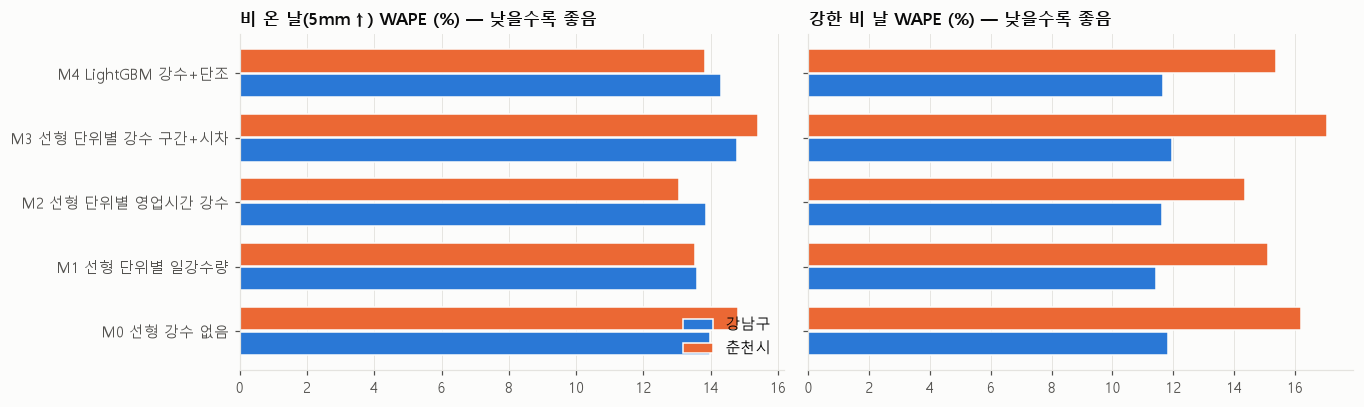

In [4]:
piv = metrics[metrics['subset'].isin(['비 온 날(5mm↑)', '강한 비 날']) & (metrics['region'] != '전체')].pivot_table(
    index='model', columns=['subset', 'region'], values='WAPE(%)')
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
names = list(MODELS)
for ax, sub in zip(axes, ['비 온 날(5mm↑)', '강한 비 날']):
    y = np.arange(len(names))
    for k, r in enumerate(REGIONS):
        ax.barh(y + (k - 0.5) * 0.38, piv.loc[names, (sub, r)], height=0.36, color=REGION_COLOR[r], label=r, edgecolor=SURFACE)
    ax.set_yticks(y, names); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
    ax.set_title(f'{sub} WAPE (%) — 낮을수록 좋음', fontsize=11)
axes[0].legend(loc='lower right')
fig.tight_layout()

In [5]:
wv = metrics[(metrics['region'] == '전체')].pivot(index='model', columns='subset', values='WAPE(%)')
cand = [m for m in MODELS if m != 'M0 선형 강수 없음']
FINAL = wv.loc[cand, '비 온 날(5mm↑)'].idxmin()
gain = wv.loc['M0 선형 강수 없음', '강한 비 날'] - wv.loc[FINAL, '강한 비 날']
print(f'최종 모델(비 온 날 WAPE 최소): {FINAL}')
print(f"강수 정보의 기여: 강한 비 날 WAPE {wv.loc['M0 선형 강수 없음', '강한 비 날']:.2f}% → {wv.loc[FINAL, '강한 비 날']:.2f}% ({gain:+.2f}%p 개선)")
print(f"일강수량(M1) vs 영업시간 강수(M2) — 비 온 날 WAPE: {wv.loc['M1 선형 단위별 일강수량', '비 온 날(5mm↑)']:.2f}% vs {wv.loc['M2 선형 단위별 영업시간 강수', '비 온 날(5mm↑)']:.2f}%")

최종 모델(비 온 날 WAPE 최소): M1 선형 단위별 일강수량
강수 정보의 기여: 강한 비 날 WAPE 12.45% → 11.96% (+0.49%p 개선)
일강수량(M1) vs 영업시간 강수(M2) — 비 온 날 WAPE: 13.58% vs 13.77%


**해석 — 최종 모델 선택**
- **최종 모델 = M1 (단위별 일강수량 계수 선형 회귀).** 비 온 날 WAPE 13.58%로 가장 낮다. 강수가 없는 기준 모델(M0) 대비 비 온 날 14.06% → 13.58%, 강한 비 날 12.45% → 11.96%로 줄어 **강수 정보가 예측에 기여**한다. 다만 개선 폭은 0.5%p 정도로 크지 않다 — 매출 변동의 대부분은 요일·연휴·계절이고, 날씨는 그 위의 작은 신호다.
- 비가 없거나 약한 날은 M0가 가장 정확하다 (10.65%). 날씨 계수가 평범한 날에는 잡음이 되기 때문이며, 이 모델의 목적은 '비 온 날 피해'이므로 비 온 날 기준으로 고른다.
- **일강수량(M1, 13.58%)이 영업시간 강수(M2, 13.77%)보다 근소하게 낫다.** 01 CH3(시간대 효과 보류)과 같은 결론이다 — 하루 강수량으로 충분하다.
- 분포 시차 모델(M3)과 LightGBM(M4)은 6개월·30개 단위 자료에서 변수 수에 비해 표본이 적어 오히려 나빠졌다. 기간 간 대체는 4절에서 고정효과 회귀로 따로 추정한다.
- 단, **예측 성능이 좋다고 피해 추정이 인과적으로 맞는 것은 아니다.** 예측 모델은 주 고정효과를 쓸 수 없어 계절 교란이 남을 수 있다 (02 3-1절, 특히 강남). 그래서 4·6절에서 논문 방법으로 교정한다.

### 3-1. 반사실 피해 (교차검증 예측)
학습에 쓴 날을 그대로 예측하면 모델이 그날을 '외운' 결과가 섞이므로, 각 날짜는 **그 날짜가 빠진 블록으로 학습한 모델**로 실제·반사실 두 시나리오를 예측한다.

In [6]:
def damage_from(models, d):
    pa, pb = np.empty(len(d)), np.empty(len(d))
    for b, m in enumerate(models):
        t = (d['block'] == b).values
        pa[t] = m.predict(d[t]); pb[t] = m.predict(no_rain(d[t]))
    return pa, pb

pa, pb = damage_from(folds[FINAL], df)
dmg = df[['date', 'region', 'industry_group', 'unit', 'block', 'amount', 'rain_sum', 'rain_light', 'rain_mid', 'rain_heavy',
          'heavy_event_id', 'weather_type', 'is_offday', 'eligible', 'damage_class_code']].copy()
dmg['rate_model'] = (np.exp(pa - pb) - 1) * 100                  # 음수 = 매출 감소
dmg['base_model'] = dmg['amount'] / (1 + dmg['rate_model'] / 100)
dmg['loss_model'] = dmg['base_model'] - dmg['amount']             # 양수 = 강수로 줄어든 매출
heavy_rate_model = dmg[dmg['rain_heavy'] == 1].groupby('region').apply(lambda g: g['loss_model'].sum() / g['base_model'].sum() * 100)  # 피해율(%), 양수 = 감소
print('예측 모델 강한 비 날 평균 피해율(%, 기준 매출 가중, 양수 = 감소):', heavy_rate_model.round(2).to_dict())

예측 모델 강한 비 날 평균 피해율(%, 기준 매출 가중, 양수 = 감소): {'강남구': 5.98, '춘천시': 9.24}


## 4. 기간 간 대체와 순손실 계수 — Roth Tran (2023) 식 (8)

비 때문에 미룬 소비를 며칠 안에 다시 한다면, 비 온 날의 감소분 중 그만큼은 '사라진 매출'이 아니다. Roth Tran(2023)은 날씨의 **선행·시차 계수를 함께 추정**해 이를 검정한다.

$$\log Y_t = \sum_{h=-3}^{7} \omega_h\,\text{강한 비}_{t-h} + \sum_{h=-3}^{7} \lambda_h\,\text{보통 비}_{t-h} + \text{요일} + \text{공휴일} + \text{월급주간} + \text{주}_{w(t)} + \varepsilon_t$$

- 논문은 7일 전 ~ 21일 후를 썼지만, 이 자료는 6개월이라 **3일 전 ~ 7일 후**로 줄인다. 선행(h < 0)은 위약 검정이다 (01 3-2절과 같은 논리).
- **0~k일 누적 효과** = Σ_{h=0..k} ω_h. 당일 효과보다 누적 효과의 손실이 작으면 그 차이만큼 '되찾은' 매출이다.
- **순손실 계수** = clip(누적 0~2일 ÷ 당일, 0, 1). 2일 이후 누적은 표준오차가 커서 보정에 쓰지 않는다. 지역 전체 매출(업종 합계)로 추정한다 (업종별은 강한 비 13~17일로 표본이 작다).

In [7]:
LEADS, LAGS = 3, 7
tot = feat.groupby(['date', 'region']).agg(amount=('amount', 'sum'), rain_heavy=('rain_heavy', 'first'),
                                           rain_mid=('rain_mid', 'first'), dow_num=('dow_num', 'first'),
                                           is_holiday=('is_holiday', 'first'), is_payday_week=('is_payday_week', 'first'),
                                           week=('week', 'first')).reset_index()
tot['log_amt'] = np.log1p(tot['amount'])
lag_name = lambda p, h: f'{p}_m{-h}' if h < 0 else f'{p}_p{h}'
it_rows, it_coef = [], []
for r in REGIONS:
    g = tot[tot['region'] == r].sort_values('date').copy()
    for p, col in [('H', 'rain_heavy'), ('M', 'rain_mid')]:
        for h in range(-LEADS, LAGS + 1):
            g[lag_name(p, h)] = g[col].shift(h)
    terms = [lag_name(p, h) for p in ('H', 'M') for h in range(-LEADS, LAGS + 1)]
    g = g.dropna(subset=terms)
    res = smf.ols('log_amt ~ ' + ' + '.join(terms) + ' + C(dow_num) + is_holiday + is_payday_week + C(week)', data=g).fit(
        cov_type='HAC', cov_kwds={'maxlags': 7})
    def combo(names):
        w = pd.Series(0.0, index=res.params.index); w[names] = 1.0
        return float(w @ res.params), float(np.sqrt(w @ res.cov_params() @ w))
    imm, imm_se = res.params['H_p0'], res.bse['H_p0']
    row = {'region': r, '강한 비 일수': int(g['rain_heavy'].sum()), '당일(%)': imm * 100, '당일 SE': imm_se * 100}
    for k in (1, 2, 3, 7):
        est, se = combo([lag_name('H', h) for h in range(0, k + 1)])
        row[f'누적 0~{k}일(%)'], row[f'누적 0~{k}일 SE'] = est * 100, se * 100
    pre, pre_se = combo([lag_name('H', h) for h in range(-LEADS, 0)])
    wt = res.wald_test(', '.join(f"{lag_name('H', h)} = 0" for h in range(-LEADS, 0)), scalar=True)
    row['선행 3일 합(%)'], row['선행 결합 p'] = pre * 100, float(wt.pvalue)
    cum2 = row['누적 0~2일(%)'] / 100
    row['순손실 계수'] = float(np.clip(cum2 / imm, 0, 1)) if imm < 0 else 0.0
    it_rows.append(row)
    for h in range(-LEADS, LAGS + 1):
        n = lag_name('H', h)
        it_coef.append({'region': r, 'h': h, 'coef_pct': res.params[n] * 100, 'se_pct': res.bse[n] * 100})
it = pd.DataFrame(it_rows).set_index('region')
it_coef = pd.DataFrame(it_coef)
it_coef['cum_pct'] = it_coef[it_coef['h'] >= 0].groupby('region')['coef_pct'].cumsum()
it.round(3).T

region,강남구,춘천시
강한 비 일수,13.000,17.000
당일(%),-1.027,-6.776
당일 SE,3.697,2.195
누적 0~1일(%),2.807,-3.824
누적 0~1일 SE,6.442,3.906
누적 0~2일(%),5.394,-4.101
누적 0~2일 SE,9.329,5.329
누적 0~3일(%),4.432,-2.276
누적 0~3일 SE,12.327,6.550
누적 0~7일(%),2.935,1.285


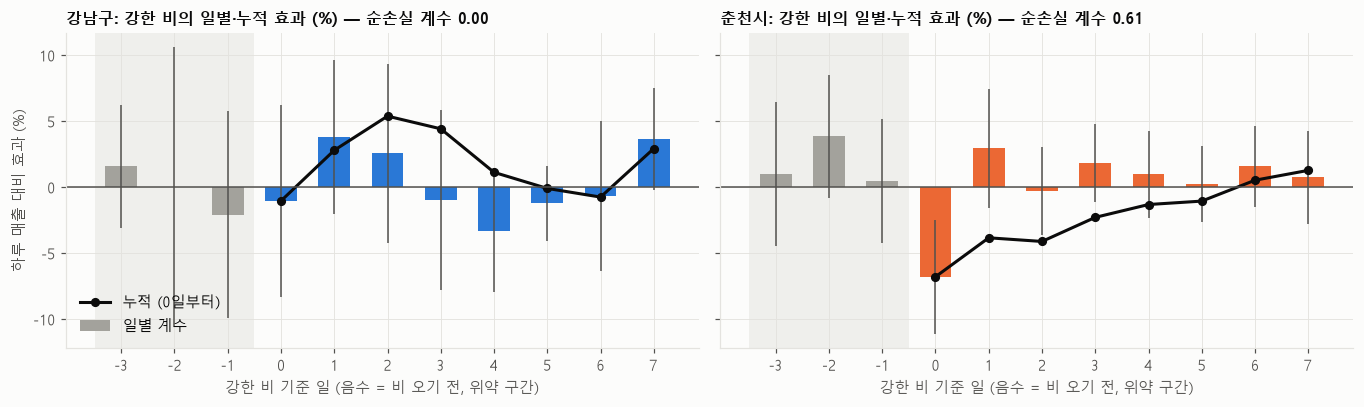

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, r in zip(axes, REGIONS):
    c = it_coef[it_coef['region'] == r]
    ax.axvspan(-LEADS - 0.5, -0.5, color=GRID, alpha=0.5, lw=0)
    ax.bar(c['h'], c['coef_pct'], color=[MUTED if h < 0 else REGION_COLOR[r] for h in c['h']], width=0.6, label='일별 계수')
    ax.errorbar(c['h'], c['coef_pct'], yerr=1.96 * c['se_pct'], fmt='none', ecolor=INK2, lw=1)
    cc = c[c['h'] >= 0]
    ax.plot(cc['h'], cc['cum_pct'], 'o-', color=INK, ms=5, label='누적 (0일부터)')
    ax.axhline(0, color=INK2, lw=1)
    ax.set_xticks(range(-LEADS, LAGS + 1))
    ax.set_xlabel('강한 비 기준 일 (음수 = 비 오기 전, 위약 구간)')
    ax.set_title(f"{r}: 강한 비의 일별·누적 효과 (%) — 순손실 계수 {it.loc[r, '순손실 계수']:.2f}", fontsize=10.5)
axes[0].set_ylabel('하루 매출 대비 효과 (%)')
axes[0].legend(loc='lower left')
fig.tight_layout()

**해석**
- **선행(비 오기 전) 3일 계수**는 두 지역 모두 결합 검정에서 0과 구분되지 않는다 (강남 p = 0.25, 춘천 p = 0.20) → 설계는 타당하다.
- **춘천**: 당일 −6.8%(SE 2.2)로 뚜렷하게 감소하고, 0~2일 누적은 −4.1%다. 즉 비 온 날 잃은 매출의 **약 40%는 이틀 안에 되돌아오고, 약 60%가 순손실**로 남는다 (순손실 계수 0.61). 다만 누적 효과의 표준오차(5.3%p)가 커서 순손실의 크기는 불확실성이 크다.
- **강남**: 당일 효과가 −1.0%(SE 3.7)로 0과 구분되지 않고 이후 누적은 오히려 양수다 → 순손실 계수 0, 즉 **순손실 근거 없음**. 이는 '손실이 없다는 증명'이 아니라 '손실이 있다는 근거가 없다'는 뜻이다.
- 이번 결과는 보통 비의 시차를 함께 통제한 것이라, 01 이벤트 스터디(강한 비만 넣음)보다 비 온 뒤 회복이 조금 더 크게 잡혔다.

## 5. LASSO 날씨 지수로 교차 확인 — Roth Tran (2023) 4절

예측 모델(3절)과 고정효과 회귀(4절)와는 **다른 방법**으로 같은 질문에 답해 본다.
1. 단위(지역×업종)마다 요일·주·공휴일·월급주간 효과를 걸러낸 **매출 잔차**와 **날씨 후보 변수 잔차**를 만든다 (논문의 고정효과 제거 단계).
2. LASSO(교차검증)로 매출 잔차를 가장 잘 설명하는 날씨 변수만 고른다. 논문은 무작위 10겹이지만, 시계열 누수를 막으려고 **주(week) 단위로 묶어** 10겹을 나눈다.
3. 예측된 잔차 = **날씨 지수**. 강한 비 날의 지수 평균을 다른 방법들과 비교한다.

후보 변수: 강수(log·구간·1·3시간 최대 대신 일강수량·전날)·체감온도·폭염 구간·최저기온·눈, 그리고 **× 춘천**, **× 업종** 상호작용 (지역·업종별 이질성).

In [9]:
cands = pd.DataFrame(index=feat.index)
for c in ['log_rain', 'rain_light', 'rain_mid', 'rain_heavy', 'log_rain_prev', 'log_rain_exposure', 'heat_excess', 'heat_33',
          'anom_feels_like', 'anom_temp_min', 'cold_excess', 'snow', 'wind_mean']:
    cands[f'f_{c}'] = feat[c].astype(float)
basef = list(cands.columns)
for c in basef:
    cands[f'{c}×춘천'] = cands[c] * feat['is_chuncheon']
for g_ in sorted(feat['industry_group'].unique()):
    d_ = (feat['industry_group'] == g_).astype(float)
    for c in ['f_log_rain', 'f_rain_heavy', 'f_heat_33']:
        cands[f'{c}×{g_}'] = cands[c] * d_
L = pd.concat([feat[KEYS + ['date', 'log_amt', 'dow_num', 'week', 'is_holiday', 'is_payday_week']], cands], axis=1)

def residualize(data, cols):
    out = pd.DataFrame(index=data.index, columns=cols, dtype=float)
    for _, g_ in data.groupby(KEYS):
        X = pd.get_dummies(g_[['dow_num', 'week']].astype(str), drop_first=True).astype(float)
        X[['is_holiday', 'is_payday_week']] = g_[['is_holiday', 'is_payday_week']].astype(float).values
        X.insert(0, 'const', 1.0)
        beta = np.linalg.lstsq(X.values, g_[cols].values, rcond=None)[0]
        out.loc[g_.index, cols] = g_[cols].values - X.values @ beta
    return out

yres = residualize(L, ['log_amt'])['log_amt'].values
Xres = residualize(L, list(cands.columns)).values
scaler = StandardScaler().fit(Xres)
Xs = scaler.transform(Xres)
gkf = GroupKFold(n_splits=10)
lasso = LassoCV(cv=list(gkf.split(Xs, yres, groups=L['week'])), random_state=42, max_iter=50000).fit(Xs, yres)
coef = pd.Series(lasso.coef_ / scaler.scale_, index=cands.columns)
sel = coef[coef != 0].sort_values()
cv_r2 = 1 - lasso.mse_path_.mean(axis=1).min() / yres.var()
L['weather_index'] = Xs @ lasso.coef_ + lasso.intercept_
print(f'후보 {cands.shape[1]}개 중 LASSO 선택 {len(sel)}개, 교차검증 잔차 R² = {cv_r2:.3f}')
display(sel.rename('계수(log, 원 단위)').to_frame().assign(
    종류=lambda x: np.where(x.index.str.contains('rain'), '강수', np.where(x.index.str.contains('heat|feels|temp|cold'), '기온', '기타'))).round(4))

후보 71개 중 LASSO 선택 25개, 교차검증 잔차 R² = 0.052


,"계수(log, 원 단위)",종류
f_rain_heavy×여가·오락,-0.091,강수
f_log_rain_exposure×춘천,-0.039,강수
f_log_rain_exposure,-0.026,강수
f_log_rain×의류·잡화,-0.023,강수
f_log_rain×여가·오락,-0.019,강수
f_snow×춘천,-0.017,기타
f_cold_excess,-0.008,기온
f_wind_mean,-0.006,기타
f_log_rain×미용·개인서비스,-0.004,강수
f_snow,-0.001,기타


In [10]:
hv = L[feat['rain_heavy'] == 1]
lasso_heavy = hv.groupby('region')['weather_index'].mean().pipe(np.exp).sub(1).mul(100)
causal_region = {}
for r in REGIONS:   # 01과 같은 주 고정효과 회귀 (지역 전체, 강한 비 당일)
    g_ = tot[tot['region'] == r].merge(feat.drop_duplicates(['date', 'region'])[['date', 'region', 'rain_light', 'heat_30_33', 'heat_33', 'snow']],
                                      on=['date', 'region'])
    res = smf.ols('log_amt ~ rain_light + rain_mid + rain_heavy + heat_30_33 + heat_33 + snow + C(dow_num) + is_holiday + is_payday_week + C(week)',
                  data=g_.sort_values('date')).fit(cov_type='HAC', cov_kwds={'maxlags': 7})
    causal_region[r] = (np.exp(res.params['rain_heavy']) - 1) * 100, res.bse['rain_heavy'] * 100
three = pd.DataFrame({
    'LASSO 날씨 지수(%)': lasso_heavy,
    '고정효과 회귀 당일(%)': {r: v[0] for r, v in causal_region.items()},
    'Roth Tran 누적 0~2일(%)': it['누적 0~2일(%)'],
    f'예측 모델 {FINAL[:2]}(%)': -heavy_rate_model,   # 효과(음수 = 감소)로 표시
})
print('강한 비 날 지역 전체 효과 — 네 가지 방법')
three.round(2)

강한 비 날 지역 전체 효과 — 네 가지 방법


,LASSO 날씨 지수(%),고정효과 회귀 당일(%),Roth Tran 누적 0~2일(%),예측 모델 M1(%)
강남구,-0.820,-1.930,5.390,-5.980
춘천시,-4.660,-7.140,-4.100,-9.240


- LASSO가 고른 25개 중 **17개가 강수 계열**이고, 가장 큰 계수는 '강한 비 × 여가·오락'(−9.1%)과 '영업시간 강수 × 춘천'이다. 기온 계열은 대부분 0에 가깝고, 큰 것은 '폭염 × 숙박'(+6.4%) 하나다 → 01의 결론(호우 중심, 폭염은 일부 업종의 소비 이동)이 **독립적인 방법으로 재현**된다. 날씨가 설명하는 몫(교차검증 잔차 R² 0.05)은 작다 — 고정효과를 뺀 뒤의 매출 변동 중 날씨 몫이 5% 정도라는 뜻이다.
- 네 방법의 강한 비 날 효과는 **춘천 −4.1 ~ −9.2%, 강남 +5.4 ~ −6.0%**로, 모든 방법에서 춘천 손실이 강남보다 크다.
- 그러나 **예측 모델(M1)은 강남 −6.0%로 고정효과 기반 세 방법(−1.9 ~ +5.4%)보다 훨씬 큰 손실**을 잡는다. 02(3-1절)에서 확인한 계절 교란이 예측 모델에 남은 것이다. 춘천은 예측 모델 −9.2%로 역시 고정효과 방법들보다 크다. 이를 6절에서 교정한다.

## 6. 인과 교정 — 예측 피해를 순손실 기준으로 맞추기

### 6-1. 업종 단위: 예측 모델과 01 인과 추정은 얼마나 맞나

업종 단위 강한 비 피해율 — 예측 모델 vs 01 인과 추정(축소)의 순위 상관 ρ = 0.64


지역 평균 강한 비 피해율 — 예측 모델: {'강남구': 5.98, '춘천시': 9.24} | 01 인과(당일): {'강남구': np.float64(1.93), '춘천시': np.float64(7.14)}


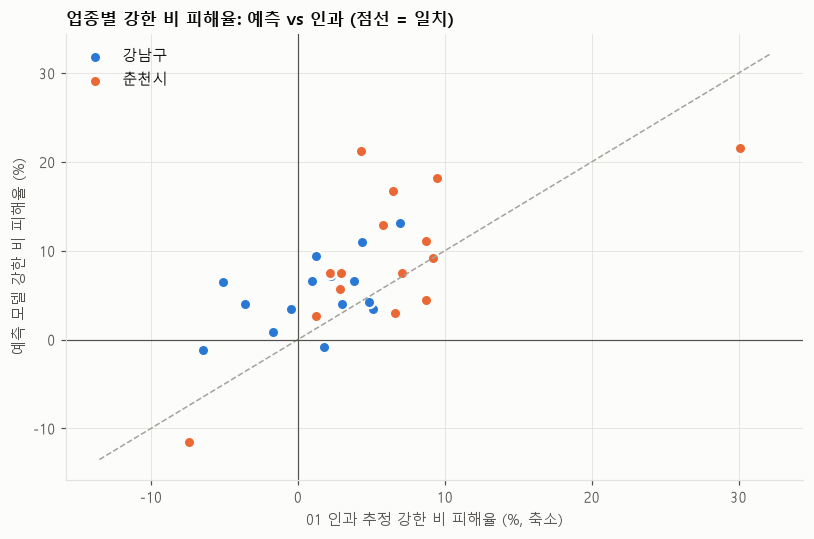

In [11]:
unit_model = dmg[dmg['rain_heavy'] == 1].groupby(KEYS).apply(lambda g: g['loss_model'].sum() / g['base_model'].sum() * 100).rename('model_heavy_rate')
uc = causal.set_index(KEYS)[['eff_rain_heavy', 'eb_rain_heavy', 'q_rain_heavy']].join(unit_model).reset_index()
rho_u = spearmanr(uc['model_heavy_rate'], -uc['eb_rain_heavy'])[0]
print(f'업종 단위 강한 비 피해율 — 예측 모델 vs 01 인과 추정(축소)의 순위 상관 ρ = {rho_u:.2f}')
fig, ax = plt.subplots(figsize=(7.5, 5))
for r in REGIONS:
    d_ = uc[uc['region'] == r]
    ax.scatter(-d_['eb_rain_heavy'], d_['model_heavy_rate'], s=55, color=REGION_COLOR[r], edgecolor=SURFACE, lw=1.5, label=r)
lim = [min(uc['model_heavy_rate'].min(), -uc['eb_rain_heavy'].max()) - 2, max(uc['model_heavy_rate'].max(), -uc['eb_rain_heavy'].min()) + 2]
ax.plot(lim, lim, ls='--', color=MUTED, lw=1)
ax.axhline(0, color=INK2, lw=0.8); ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel('01 인과 추정 강한 비 피해율 (%, 축소)'); ax.set_ylabel('예측 모델 강한 비 피해율 (%)')
ax.set_title('업종별 강한 비 피해율: 예측 vs 인과 (점선 = 일치)', fontsize=11)
ax.legend()
fig.tight_layout()
print('지역 평균 강한 비 피해율 — 예측 모델:', heavy_rate_model.round(2).to_dict(),
      '| 01 인과(당일):', {r: round(-v[0], 2) for r, v in causal_region.items()})

### 6-2. 교정 방법
예측 모델은 **업종·날짜별 피해의 상대적 크기**(어느 업종이, 비가 얼마나 올 때 더 잃나)를 잘 잡지만, **지역 전체 수준**은 계절 교란 때문에 부풀 수 있다. 그래서 수준은 인과 추정에 맞추고, 상대적 차이는 모델에서 가져온다.

$$\text{교정 피해율}_{u,t} = \text{예측 피해율}_{u,t} \times k_r, \qquad k_r = \frac{\text{지역 } r \text{ 의 인과 순손실 효과 (Roth Tran 누적 0~2일)}}{\text{지역 } r \text{ 의 예측 모델 강한 비 피해율}} \;\; (0 \le k_r)$$

- 인과 순손실 효과(4절 누적 0~2일)가 손실이 아니면(≥ 0) $k_r = 0$ → 그 지역은 **순손실 근거 없음**.
- 강수 강도에 따른 차이와 업종 간 차이는 모델의 것을 그대로 쓴다.
- 4절의 95% 신뢰구간 양 끝으로도 $k_r$을 계산해 **피해의 하한·상한**을 함께 둔다.

In [12]:
cal_rows = []
for r in REGIONS:
    net, se = it.loc[r, '누적 0~2일(%)'], it.loc[r, '누적 0~2일 SE']
    model = heavy_rate_model[r]
    k = lambda target: max(0.0, -target / model) if model > 0 else 0.0
    cal_rows.append({'region': r, '예측 모델 강한 비 피해율(%)': model, '인과 순손실 효과 0~2일(%)': net,
                     '95% CI 손실 큰 쪽(%)': net - 1.96 * se, '95% CI 손실 작은 쪽(%)': net + 1.96 * se,
                     'k (중심)': k(net), 'k (손실 큰 쪽)': k(net - 1.96 * se), 'k (손실 작은 쪽)': k(net + 1.96 * se)})
calib = pd.DataFrame(cal_rows).set_index('region')
display(calib.round(3))
for col, kcol in [('rate', 'k (중심)'), ('rate_hi', 'k (손실 큰 쪽)'), ('rate_lo', 'k (손실 작은 쪽)')]:
    dmg[col] = dmg['rate_model'] * dmg['region'].map(calib[kcol])
dmg['base'] = dmg['amount'] / (1 + dmg['rate'] / 100)
dmg['loss'] = dmg['base'] - dmg['amount']
dmg['loss_hi'] = dmg['amount'] / (1 + dmg['rate_hi'] / 100) - dmg['amount']
dmg['loss_lo'] = dmg['amount'] / (1 + dmg['rate_lo'] / 100) - dmg['amount']

tt = dmg.groupby('region').agg(sales=('amount', 'sum'), loss_model=('loss_model', lambda s: s.clip(lower=0).sum()),
                               loss=('loss', lambda s: s.clip(lower=0).sum()), loss_lo=('loss_lo', lambda s: s.clip(lower=0).sum()),
                               loss_hi=('loss_hi', lambda s: s.clip(lower=0).sum()))
view = (tt / 1e8).round(1)
view['교정 전 손실/매출(%)'] = (tt['loss_model'] / tt['sales'] * 100).round(2)
view['교정 후 손실/매출(%)'] = (tt['loss'] / tt['sales'] * 100).round(2)
print('분석 기간(7/15~12/31) 강수 손실 합계 (억원, 신한카드 기준) — 교정 전 vs 교정 후(하한~상한)')
view.rename(columns={'sales': '매출', 'loss_model': '교정 전 손실', 'loss': '교정 후 손실', 'loss_lo': '교정 후 하한', 'loss_hi': '교정 후 상한'})

,예측 모델 강한 비 피해율(%),인과 순손실 효과 0~2일(%),95% CI 손실 큰 쪽(%),95% CI 손실 작은 쪽(%),k (중심),k (손실 큰 쪽),k (손실 작은 쪽)
region,,,,,,,
강남구,5.981,5.394,-12.891,23.680,0.000,2.155,0.000
춘천시,9.238,-4.101,-14.546,6.344,0.444,1.575,0.000


분석 기간(7/15~12/31) 강수 손실 합계 (억원, 신한카드 기준) — 교정 전 vs 교정 후(하한~상한)


,매출,교정 전 손실,교정 후 손실,교정 후 하한,교정 후 상한,교정 전 손실/매출(%),교정 후 손실/매출(%)
region,,,,,,,
강남구,"110,157.100","1,642.900",0.000,0.000,"3,955.100",1.490,0.000
춘천시,"14,061.300",259.200,107.900,0.000,440.600,1.840,0.770


**해석**
- **업종 간 상대 순서는 예측과 인과가 비슷하다** (6-1절 ρ = 0.64). 예측 모델은 '어느 업종이 더 잃나'는 대체로 맞힌다.
- 그러나 **수준은 크게 다르다.** 예측 모델만으로 재면 분석 기간 강수 손실이 강남 약 1,643억원·춘천 약 259억원이지만, 인과 순손실로 교정하면 **강남 0원(순손실 근거 없음)·춘천 약 108억원**이다 (교정 계수 강남 0, 춘천 0.44).
- 불확실성은 크다: 순손실 효과의 95% 신뢰구간 양 끝으로 교정하면 두 지역 모두 '0 ~ 교정 전보다 큰 값'까지 걸친다 (상한: 강남 3,955억원·춘천 441억원). 6개월·강한 비 13~17일 자료의 한계다. 그래서 중심값만이 아니라 **하한·상한을 함께** 4·5단계로 넘긴다.
- 이 차이가 6단계 문제 발굴의 핵심 근거다: **어떤 방법으로 피해를 재느냐에 따라 '어느 지역에 얼마의 피해가 있었나'가 크게 달라지고**, 그대로 지원 배분이 달라진다. 예측 모델만 쓰면 피해의 약 86%가 강남으로 잡히지만, 인과적으로 확인되는 손실은 춘천에만 있다.

## 7. 피해 분류 모델 — 예보로 '피해일'을 미리 알 수 있나

지원을 **사전에**(D-1 예보 시점) 하려면 '내일 이 업종에 큰 피해가 날 것인가'를 분류할 수 있어야 한다.

| 항목 | 정의 |
|---|---|
| 레이블 (관측 기반) | **피해일** = 실제 매출이 강수 없는 기준 모델(M0)의 교차검증 예측보다 **10% 이상 낮은 날** (단위 × 날짜). 모델이 만든 피해가 아니라 **관측된 하락**이라 순환 논리가 아니다 |
| 입력 A (달력만) | 단위, 요일, 공휴일·연휴, 계절 레이블, 최근 매출 수준 |
| 입력 B (달력 + 예보 기상) | A + 일강수량·영업시간 강수·전날 강수·연속 강수일·폭염·눈 (예보를 '완벽한 예보 = 실제 관측'으로 가정) |
| 규칙 기준선 | "일강수량 30mm 이상이면 피해일" (현행 호우 기준과 비슷한 단순 규칙) |
| 모델 | 로지스틱 회귀(표준화 파이프라인), LightGBM 분류 |
| 검증 | 같은 날짜 블록 교차검증, ROC-AUC·PR-AUC(피해일이 드물어 PR-AUC가 중요) |

In [13]:
resid = np.log1p(df['amount']) - oof['M0 선형 강수 없음']
df['damage_day'] = (np.exp(resid) - 1 <= -0.10).astype(int)
print(f"피해일 비율: 전체 {df['damage_day'].mean():.1%} | 강한 비 날 {df.loc[df['rain_heavy'] == 1, 'damage_day'].mean():.1%} | "
      f"비 없는 날 {df.loc[df['rain_sum'] == 0, 'damage_day'].mean():.1%}")
CAL_F = ['unit_code', 'region_code', 'industry_code', 'dow_num', 'is_holiday', 'is_offday', 'holiday_prev', 'holiday_next',
         'is_payday_week', 'summer_peak', 'long_holiday', 'long_holiday_pre', 'long_holiday_post', 'lag7', 'lag14', 'roll7']
WX_F = ['log_rain', 'log_rain_exposure', 'log_rain_prev', 'rain_streak', 'rain_heavy', 'rain_mid', 'heat_33', 'snow',
        'rain_heavy_x_chuncheon', 'rain_heavy_x_outsider']
clf_rows, clf_pred = [], {}
for fs_name, fs in [('A 달력만', CAL_F), ('B 달력 + 예보 기상', CAL_F + WX_F)]:
    for mname in ['로지스틱', 'LightGBM']:
        p = np.empty(len(df))
        for b in range(N_BLOCKS):
            te = (df['block'] == b).values
            if mname == '로지스틱':
                X = pd.get_dummies(df[fs].astype({'unit_code': str, 'dow_num': str}), columns=['unit_code', 'dow_num'], dtype=float)
                m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(X[~te], df.loc[~te, 'damage_day'])
                p[te] = m.predict_proba(X[te])[:, 1]
            else:
                m = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8,
                                       subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)
                m.fit(df.loc[~te, fs], df.loc[~te, 'damage_day'], categorical_feature=['unit_code'])
                p[te] = m.predict_proba(df.loc[te, fs])[:, 1]
        clf_pred[(fs_name, mname)] = p
        y = df['damage_day']
        for sub, mask in [('전체', np.ones(len(df), bool)), ('비 온 날(5mm↑)', (df['rain_sum'] >= 5).values)]:
            clf_rows.append({'입력': fs_name, '모델': mname, '범위': sub, 'ROC-AUC': roc_auc_score(y[mask], p[mask]),
                             'PR-AUC': average_precision_score(y[mask], p[mask]), '피해일 비율': y[mask].mean()})
rule = df['rain_heavy'].values.astype(float)
for sub, mask in [('전체', np.ones(len(df), bool)), ('비 온 날(5mm↑)', (df['rain_sum'] >= 5).values)]:
    clf_rows.append({'입력': '규칙', '모델': '강수 30mm 이상', '범위': sub, 'ROC-AUC': roc_auc_score(df['damage_day'][mask], rule[mask]),
                     'PR-AUC': average_precision_score(df['damage_day'][mask], rule[mask]), '피해일 비율': df['damage_day'][mask].mean()})
clf = pd.DataFrame(clf_rows)
clf.pivot_table(index=['입력', '모델'], columns='범위', values=['ROC-AUC', 'PR-AUC']).round(3)

피해일 비율: 전체 22.0% | 강한 비 날 34.9% | 비 없는 날 18.7%


PR-AUC           ROC-AUC      
범위                      비 온 날(5mm↑)    전체 비 온 날(5mm↑)    전체
입력           모델                                            
A 달력만        LightGBM         0.402 0.307       0.576 0.621
             로지스틱             0.348 0.249       0.509 0.559
B 달력 + 예보 기상 LightGBM         0.417 0.326       0.580 0.639
             로지스틱             0.361 0.270       0.516 0.575
규칙           강수 30mm 이상       0.345 0.238       0.507 0.533

In [14]:
best = clf[(clf['범위'] == '전체') & (clf['입력'] != '규칙')].sort_values('PR-AUC', ascending=False).iloc[0]
pb_ = clf_pred[(best['입력'], best['모델'])]
dd = df[['region', 'industry_group', 'rain_heavy', 'damage_day']].assign(p=pb_)
top = dd[dd['rain_heavy'] == 1]
by_u = top.groupby(KEYS).agg(강한비날_피해일비율=('damage_day', 'mean'), 평균_예측확률=('p', 'mean')).reset_index()
rho_c = spearmanr(by_u['강한비날_피해일비율'], by_u['평균_예측확률'])[0]
print(f"최고 분류 모델: {best['입력']} · {best['모델']} (PR-AUC {best['PR-AUC']:.3f})")
print(f"강한 비 날 업종별 '실제 피해일 비율' vs '예측 확률' 순위 상관 ρ = {rho_c:.2f}")
by_u.sort_values('평균_예측확률', ascending=False).head(10).round(3)

최고 분류 모델: B 달력 + 예보 기상 · LightGBM (PR-AUC 0.326)
강한 비 날 업종별 '실제 피해일 비율' vs '예측 확률' 순위 상관 ρ = 0.88


,region,industry_group,강한비날_피해일비율,평균_예측확률
21,춘천시,숙박,0.647,0.563
12,강남구,주점·유흥,0.462,0.528
23,춘천시,여가·오락,0.588,0.519
1,강남구,교육,0.462,0.508
18,춘천시,기타소매,0.529,0.495
25,춘천시,의료·보건,0.529,0.463
26,춘천시,의류·잡화,0.471,0.441
7,강남구,식료품소매,0.462,0.438
6,강남구,숙박,0.385,0.414
16,춘천시,교육,0.353,0.411


**해석**
- 피해일(평소보다 10% 이상 낮은 날)은 전체의 22%지만, 강한 비 날에는 35%로 높다.
- **최고 모델은 '달력 + 예보 기상' LightGBM** (ROC-AUC 0.64, PR-AUC 0.33). 달력만 쓴 같은 모델(0.62, 0.31)보다 낫지만 **기상이 더해 주는 정보는 크지 않다** (+0.02). 예보 하나만으로 피해일을 정확히 맞히기는 어렵다.
- **"30mm 이상이면 피해" 규칙은 가장 약하다** (ROC-AUC 0.53, PR-AUC 0.24). 모든 업종을 같게 취급하기 때문이다.
- 반면 강한 비 날 **업종별 실제 피해일 비율과 모델 예측 확률의 순위 상관은 0.88**이다. 즉 '언제'보다 **'어느 업종이' 피해를 입는지**가 훨씬 잘 예측된다 (춘천 숙박·여가·오락·기타소매 등). → 업종의 취약성을 따로 측정하는 **4단계 취약도 지수가 필요한 근거**다.
- 한계: 레이블은 기준 모델의 오차에도 영향을 받고, 예보를 '완벽한 예보'로 가정했다 (실제 예보 오차가 있으면 성능은 낮아진다).

## 8. 연간 예상 손실 — 기후 빈도 환산 (Auffhammer et al., 2013)

6개월 피해를 2배 하면 계절이 치우친다(여름 장마 포함, 1~6월 없음). 그래서 **강수 유형별 하루 평균 피해**에 **2015~2024년 연평균 발생 일수**를 곱한다.
$$\text{연간 예상 손실}_u = \sum_{k \in \{\text{약한 비, 보통 비, 강한 비}\}} \overline{\text{하루 교정 손실}}_{u,k} \times \overline{\text{연간 일수}}_{r,k}$$
- 하루 손실이 음수(비 온 날 매출 증가)면 0으로 둔다 (지원은 손실에만).
- 하한·상한 시나리오도 같은 방식으로 계산한다.

In [15]:
kma = pd.read_csv(KMA_DAILY, usecols=['stnId', 'tm', 'sumRn'])
kma['region'] = kma['stnId'].map({108: '강남구', 101: '춘천시'})
kma['year'] = kma['tm'].str[:4]
kma['sumRn'] = kma['sumRn'].fillna(0)
freq = kma.groupby(['region', 'year']).agg(
    약한비=('sumRn', lambda s: ((s > 0) & (s < 5)).sum()), 보통비=('sumRn', lambda s: ((s >= 5) & (s < 30)).sum()),
    강한비=('sumRn', lambda s: (s >= 30).sum())).groupby('region').mean()
print('연평균 강수 유형별 일수 (2015~2024, 기상청 ASOS)')
display(freq.round(1))

types = {'약한비': dmg['rain_light'] == 1, '보통비': dmg['rain_mid'] == 1, '강한비': dmg['rain_heavy'] == 1}
unit_info = feat.drop_duplicates(KEYS).set_index(KEYS)[['outsider_share', 'indep_share', 'eligible']]
uprof = load('unit_profile').set_index(KEYS)[['n_stores', 'sales_monthly', 'sales_per_store_monthly', 'base_daily_sales']]
summary = uprof.join(unit_info).join(causal.set_index(KEYS)[['eb_rain_heavy', 'q_rain_heavy']])
for scen, col in [('', 'loss'), ('_lo', 'loss_lo'), ('_hi', 'loss_hi'), ('_model', 'loss_model')]:
    per_day = pd.DataFrame({k: dmg[m].groupby(KEYS)[col].mean() for k, m in types.items()}).clip(lower=0).fillna(0)
    annual = per_day.mul(freq.reindex(per_day.index.get_level_values(0)).values)
    summary[f'annual_loss{scen}'] = annual.sum(axis=1)
    if scen == '':
        for k in types:
            summary[f'loss_day_{k}'] = per_day[k]
            summary[f'annual_loss_{k}'] = annual[k]
heavy_rate = dmg[dmg['rain_heavy'] == 1].groupby(KEYS).apply(lambda g: g['loss'].sum() / g['base'].sum() * 100)
summary['heavy_rate'] = heavy_rate
summary['heavy_rate_model'] = unit_model
summary['annual_loss_per_store'] = summary['annual_loss'] / summary['n_stores']
summary['annual_loss_rate'] = summary['annual_loss'] / (summary['sales_monthly'] * 12) * 100
summary['annual_loss_rate_model'] = summary['annual_loss_model'] / (summary['sales_monthly'] * 12) * 100
summary = summary.reset_index()
v = summary.sort_values('annual_loss', ascending=False)[KEYS + ['annual_loss_model', 'annual_loss', 'annual_loss_lo', 'annual_loss_hi',
                                                              'annual_loss_per_store', 'annual_loss_rate', 'heavy_rate']].copy()
for c in ['annual_loss_model', 'annual_loss', 'annual_loss_lo', 'annual_loss_hi']:
    v[c] = v[c] / 1e8
v['annual_loss_per_store'] /= 1e4
v.rename(columns={'annual_loss_model': '교정 전(억원)', 'annual_loss': '교정 후(억원)', 'annual_loss_lo': '하한(억원)',
                  'annual_loss_hi': '상한(억원)', 'annual_loss_per_store': '점포당(만원)', 'annual_loss_rate': '연매출 대비(%)',
                  'heavy_rate': '강한 비 피해율(%)'}).round(2).head(15)

연평균 강수 유형별 일수 (2015~2024, 기상청 ASOS)


,약한비,보통비,강한비
region,,,
강남구,61.700,31.600,13.000
춘천시,56.700,33.800,12.000


,region,industry_group,교정 전(억원),교정 후(억원),하한(억원),상한(억원),점포당(만원),연매출 대비(%),강한 비 피해율(%)
24,춘천시,음식점,62.060,26.700,0.000,101.090,80.110,0.370,3.330
17,춘천시,교통·자동차,54.790,23.220,0.000,90.780,451.820,0.550,4.930
23,춘천시,여가·오락,39.870,15.640,0.000,73.140,227.260,0.960,9.310
18,춘천시,기타소매,36.180,15.000,0.000,61.660,110.160,0.870,7.410
19,춘천시,대형유통,31.900,13.320,0.000,53.640,327.270,0.270,3.240
25,춘천시,의료·보건,29.810,12.900,0.000,48.240,222.820,0.330,2.540
22,춘천시,식료품소매,24.220,10.140,0.000,40.730,206.930,0.580,5.650
26,춘천시,의류·잡화,21.220,8.720,0.000,36.550,84.450,0.900,8.060
28,춘천시,카페·디저트,6.100,2.590,0.000,10.090,22.950,0.430,4.020
29,춘천시,편의점,5.940,2.580,0.000,9.550,69.290,0.160,1.310


In [16]:
reg_sum = summary.groupby('region')[['annual_loss_model', 'annual_loss', 'annual_loss_lo', 'annual_loss_hi']].sum() / 1e8
print('지역별 연간 예상 강수 손실 (억원, 신한카드 기준)')
display(reg_sum.rename(columns={'annual_loss_model': '교정 전', 'annual_loss': '교정 후', 'annual_loss_lo': '하한',
                                'annual_loss_hi': '상한'}).round(1))
el = summary[summary['eligible'] == 1]
pos_ = el[el['annual_loss'] > 0]
print(f"지원 자격 업종 중 교정 후 손실 > 0 인 {len(pos_)}개: 연간 손실 '금액' 순위 vs '연매출 대비 비율' 순위 "
      f"ρ = {spearmanr(pos_['annual_loss'], pos_['annual_loss_rate'])[0]:.2f}")
top_amt = set(pos_.nlargest(5, 'annual_loss')['industry_group']); top_rate = set(pos_.nlargest(5, 'annual_loss_rate')['industry_group'])
print(f"  금액 상위 5: {sorted(top_amt)} | 비율 상위 5: {sorted(top_rate)} | 겹침 {len(top_amt & top_rate)}개")
top_m = set(el.nlargest(8, 'annual_loss_model')[KEYS].apply(' '.join, axis=1))
top_c = set(el.nlargest(8, 'annual_loss')[KEYS].apply(' '.join, axis=1))
print(f"손실 금액 상위 8개 — 교정 전과 교정 후의 겹침: {len(top_m & top_c)}개 | 교정 전에만 있는 업종: {sorted(top_m - top_c)}")

지역별 연간 예상 강수 손실 (억원, 신한카드 기준)


,교정 전,교정 후,하한,상한
region,,,,
강남구,"1,592.200",0.000,0.000,"3,852.200"
춘천시,323.000,135.400,0.000,543.900


지원 자격 업종 중 교정 후 손실 > 0 인 13개: 연간 손실 '금액' 순위 vs '연매출 대비 비율' 순위 ρ = 0.35
  금액 상위 5: ['교통·자동차', '기타소매', '여가·오락', '음식점', '의료·보건'] | 비율 상위 5: ['기타소매', '숙박', '식료품소매', '여가·오락', '의류·잡화'] | 겹침 2개
손실 금액 상위 8개 — 교정 전과 교정 후의 겹침: 3개 | 교정 전에만 있는 업종: ['강남구 교육', '강남구 미용·개인서비스', '강남구 음식점', '강남구 의료·보건', '강남구 의류·잡화']


**해석**
- **연간 예상 강수 손실**: 교정 전(예측 모델 그대로) 강남 약 1,592억원·춘천 약 323억원 → 교정 후 **강남 0원·춘천 약 135억원** (신한카드 기준, 범위 0 ~ 강남 3,852억·춘천 544억원).
- 손실 금액 상위 8개 업종도 교정 전·후에 3개만 겹친다. 교정 전에는 강남 교육·미용·음식점·의료·보건·의류·잡화가 상위였지만, 교정 후에는 모두 빠진다.
- 춘천 안에서는 금액 상위(음식점·교통·자동차·여가·오락 등)와 연매출 대비 비율 상위(숙박·여가·오락·의류·잡화·기타소매·식료품소매)가 다르다 (순위 상관 0.35, 상위 5개 중 2개만 겹침) — 01 CH5와 같은 구조로, 금액 순 지원이 타격이 큰 업종을 놓칠 수 있다.
- 이 표(`damage_unit_summary`)가 4단계 취약도 지수의 **피해도** 요소와 5단계 최적화의 **예상 손실** 입력이 된다.

## 9. 저장·정리

In [17]:
metrics.to_csv(REF / 'damage_model_metrics.csv', index=False, encoding='utf-8-sig', float_format='%.4f')
calib.join(it[['당일(%)', '누적 0~2일(%)', '누적 0~7일(%)', '선행 결합 p', '순손실 계수']]).to_csv(
    REF / 'damage_calibration.csv', encoding='utf-8-sig', float_format='%.4f')
dmg.to_parquet(PROC / 'damage_daily.parquet', index=False)
summary.to_parquet(PROC / 'damage_unit_summary.parquet', index=False)
print('저장: damage_daily', dmg.shape, '| damage_unit_summary', summary.shape)
print('저장: references/damage_model_metrics.csv, references/damage_calibration.csv')

저장: damage_daily (5100, 25) | damage_unit_summary (30, 26)
저장: references/damage_model_metrics.csv, references/damage_calibration.csv


## 정리

| 항목 | 결과 |
|---|---|
| 피해 정의 | 반사실 예측: '실제 강수' vs '강수 없음' (폭염·눈은 실제값 유지 → **강수 피해**) |
| 모델 비교 | **M1 단위별 일강수량 선형 모델** 선택 (비 온 날 WAPE 13.58%, 강수 없는 모델 대비 −0.5%p). 영업시간 강수(M2)는 근소하게 열세 |
| 기간 간 대체 (Roth Tran 2023 식 8) | 위약(선행) 통과. 춘천은 비 온 날 손실의 약 60%가 순손실(계수 0.61), 강남은 순손실 근거 없음(계수 0) |
| LASSO 날씨 지수 (Roth Tran 2023 4절) | 선택 변수 25개 중 17개가 강수 계열 → 01 결론(호우 중심)을 독립적으로 재현 |
| 인과 교정 | 업종 순서는 예측·인과가 비슷(ρ = 0.64)하지만 수준은 다름. 분석 기간 손실 강남 1,643억 → 0원, 춘천 259억 → 108억원 |
| 피해 분류 | 최고 모델 ROC-AUC 0.64·PR-AUC 0.33 (30mm 규칙 0.53·0.24). 기상의 추가 정보는 작고, **업종별 피해 경향**은 잘 예측(ρ = 0.88) |
| 연간 예상 손실 | 교정 전 강남 1,592억·춘천 323억 → 교정 후 강남 0원·춘천 135억원 (넓은 불확실성 범위 함께 보고) |
| 산출물 | `damage_daily`, `damage_unit_summary`, `references/damage_model_metrics.csv`, `references/damage_calibration.csv` |

### 다음 단계(04 취약도 지수)에 넘기는 것
- **피해도** 요소 = 교정 후 연간 손실률(연매출 대비)·점포당 손실, **민감도** = 01 인과 피해율, 하한·상한 시나리오는 지수 불확실성 분석의 한 단계로
- 분류 결과: 같은 비라도 업종에 따라 피해일이 다르다 → 취약도 지수로 '누가 피해를 입을지'를 사전에 구분

### 참고문헌
- Roth Tran, B. (2023). Sellin' in the Rain: Weather, Climate, and Retail Sales. *Management Science*, 69(12). 워킹페이퍼: https://www.frbsf.org/wp-content/uploads/wp2022-02.pdf
- Dell, M., Jones, B. F., & Olken, B. A. (2014). What Do We Learn from the Weather? The New Climate-Economy Literature. *Journal of Economic Literature*, 52(3), 740–798.
- Auffhammer, M., Hsiang, S. M., Schlenker, W., & Sobel, A. (2013). Using Weather Data and Climate Model Output in Economic Analyses. *Review of Environmental Economics and Policy*, 7(2), 181–198.